<a href="https://colab.research.google.com/github/sany1133/CMP6202-Coursework/blob/main/notebooks/01_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import pandas as pd

In [23]:
url = "https://raw.githubusercontent.com/sany1133/CMP6202-Coursework/main/data/SMSSpamCollection"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 1. Dataset Exploration

In [24]:
df.shape

(5572, 2)

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [26]:
df.isnull().sum()

,0
label,0
message,0


In [27]:
df["label"].value_counts()

,count
label,
ham,4825
spam,747


In [28]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 403
Dataset shape after removing duplicates: (5169, 2)


## 2. Exploratory Data Analysis (EDA)

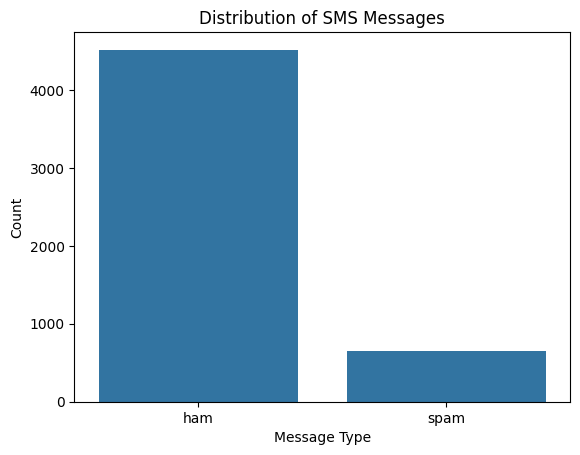

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")
plt.title("Distribution of SMS Messages")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

In [30]:
df["message_length"] = df["message"].str.len()

df.groupby("label")["message_length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.905890,56.715046,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.704441,29.821348,13.0,132.0,148.0,157.0,223.0


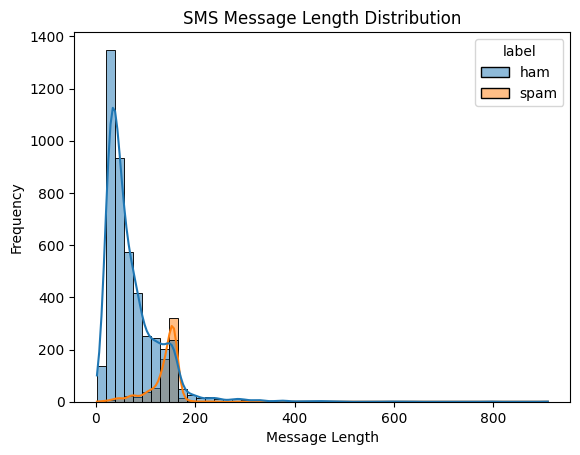

In [31]:
sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=50,
    kde=True
)

plt.title("SMS Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")
plt.show()

## 3. Data Preprocessing

In [32]:
df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df[["label", "message", "target"]].head()

,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 4. Train, Validation and Test Split

In [33]:
from sklearn.model_selection import train_test_split

X = df["message"]
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 3101
Validation: 1034
Testing: 1034


## 5. Text Vectorization

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (3101, 5000)
Validation shape: (1034, 5000)
Testing shape: (1034, 5000)


## 6. Baseline Model

In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_tfidf, y_train)

baseline_pred = baseline.predict(X_val_tfidf)

print("Baseline Accuracy:", accuracy_score(y_val, baseline_pred))
print("Baseline Precision:", precision_score(y_val, baseline_pred, zero_division=0))
print("Baseline Recall:", recall_score(y_val, baseline_pred, zero_division=0))
print("Baseline F1:", f1_score(y_val, baseline_pred, zero_division=0))

Baseline Accuracy: 0.8733075435203095
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0


## 7. Machine Learning Model Training

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "Support Vector Machine": LinearSVC(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(f"{name}: Training completed")

Logistic Regression: Training completed
Naive Bayes: Training completed
Support Vector Machine: Training completed
Random Forest: Training completed
Decision Tree: Training completed
KNN: Training completed
Gradient Boosting: Training completed


## 8. Model Evaluation and Comparison

In [37]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_val_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
2,Support Vector Machine,0.985493,0.975410,0.908397,0.940711
3,Random Forest,0.980658,0.991150,0.854962,0.918033
1,Naive Bayes,0.973888,1.000000,0.793893,0.885106
4,Decision Tree,0.957447,0.804196,0.877863,0.839416
6,Gradient Boosting,0.962282,0.979167,0.717557,0.828194
0,Logistic Regression,0.955513,0.977528,0.664122,0.790909
5,KNN,0.911025,1.000000,0.297710,0.458824


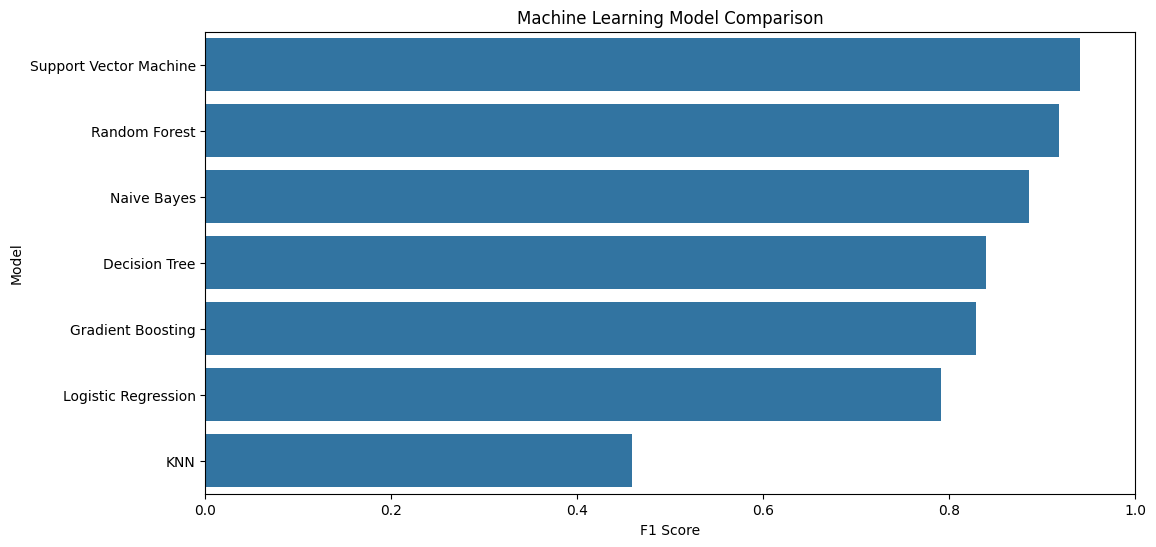

In [38]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="F1 Score",
    y="Model"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("F1 Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

## 9. Best Model Selection

In [39]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Validation F1 Score:", results_df.iloc[0]["F1 Score"])

Best Model: Support Vector Machine
Validation F1 Score: 0.9407114624505929


## 10. Final Model Evaluation

In [40]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_test_pred = best_model.predict(X_test_tfidf)

print("Best Model:", best_model_name)
print()
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

Best Model: Support Vector Machine

              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       904
        Spam       0.96      0.84      0.89       130

    accuracy                           0.97      1034
   macro avg       0.97      0.92      0.94      1034
weighted avg       0.97      0.97      0.97      1034



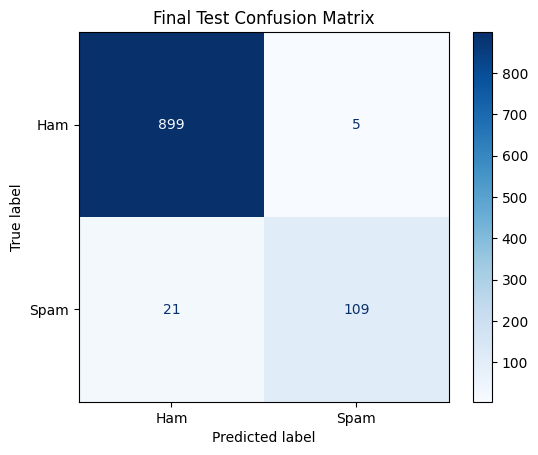

In [41]:
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Final Test Confusion Matrix")
plt.show()

## 11. Real-World SMS Predictions

In [42]:
sample_messages = [
    "Hey, are we still meeting at 6 tonight?",
    "Congratulations! You have won a free iPhone. Claim your prize now!",
    "Can you call me when you get home?",
    "URGENT! You have won £1000. Text WIN to claim your reward.",
    "Your appointment is confirmed for tomorrow at 10 AM."
]

sample_tfidf = vectorizer.transform(sample_messages)
predictions = best_model.predict(sample_tfidf)

for message, prediction in zip(sample_messages, predictions):
    label = "SPAM" if prediction == 1 else "HAM"
    print(f"{label}: {message}")

HAM: Hey, are we still meeting at 6 tonight?
SPAM: Congratulations! You have won a free iPhone. Claim your prize now!
HAM: Can you call me when you get home?
SPAM: URGENT! You have won £1000. Text WIN to claim your reward.
HAM: Your appointment is confirmed for tomorrow at 10 AM.
